# T9EditorLIT — Theme System

**Clipchamp dark · Nanami · Clipchamp light** — one token namespace, three palettes, zero-re-render switching.

> Hinglish TL;DR: ek baar tokens likh do, phir sirf `<html data-theme="...">` badlo — poori app ka rang badal jaata hai, koi component dobara render nahi hota. Neeche thoughts, live screenshots aur copy-paste-ready code hai.

This notebook is **self-contained**: the screenshots are embedded as base64 attachments and the code cells are generated from the real source files by `docs/theme-logic/build.ps1`. Re-run that script after changing the theme and this document updates itself.

## What lives where

| Piece | File | Job |
| --- | --- | --- |
| Token definitions + 3 palettes | `src/app.css` | `@theme static` block + two unlayered `[data-theme=…]` overrides |
| Pre-paint restore | `static/theme-init.js` | Reads `localStorage` before first paint, sets `data-theme` |
| Runtime switch (writer) | `src/lib/stores/theme.svelte.ts` | Svelte 5 rune store: `set` / `toggle` / `next` |
| HTML shell | `src/app.html` | `<html class="dark" data-theme="clipchamp">` + `<meta color-scheme>` |
| Toggle UI | `src/lib/components/clipchamp/CcTopBar.svelte` | Moon/Sun button + `CcMenu` radio list |

## Requirements

- Svelte 5 (runes) + Tailwind CSS v4 — the `@theme static` block is v4 syntax.
- Works in a plain Vite SPA too; the SvelteKit-specific `%sveltekit.assets%` markers can be replaced with plain relative paths.

## Thought process — why it is built this way

These are decisions, not accidents. Each one has a failure mode it exists to prevent.

1. **One namespace, values only swap.** Components are written against *names* (`--color-cc-surface`, `--color-cc-link`), never against hex codes. Adding a fourth theme means adding one CSS block and one array entry — zero component edits.

2. **Switch by attribute, not by state.** `document.documentElement.setAttribute("data-theme", …)` and the CSS cascade does the rest. No `if (theme === 'dark')` in markup, no re-render of a 3,000-node editor tree, no flash of the wrong palette mid-switch.

3. **`@theme static`, not `@theme`.** Tailwind v4 normally tree-shakes unused tokens. A token referenced only inside an `svg fill="var(--color-cc-purple)"` attribute is invisible to that scan, so the token never gets emitted and the fill silently disappears. `static` forces every token to be written out.

4. **Theme overrides are deliberately UNLAYERED.** Tailwind emits `@theme` into `@layer theme`, and an unlayered rule always outranks any layered one regardless of source order. That is what makes `[data-theme="nanami"]` reliably beat the base block on the same element — no `!important`, no specificity games, no source-order fragility.

5. **The purple ramp is role-based, not a gradient.** In a dark UI the *opposite* ordering from a light one is needed for the same jobs:
   - `purple` — brand accent: focus rings, rail indicator, borders. **Never** carries text.
   - `btn` / `btn-hover` — filled primary button; the contrast-checked version that clears 4.5:1 with white text.
   - `link` — accent **text** on a panel, the bright end of the ramp.
   - `lilac` / `blush` — decorative fills only.
6. **No flash on launch.** `static/theme-init.js` runs from `<head>` before the first paint, so a user who left it on Nanami never sees a dark-purple frame first. It is an **external** file because Tauri ships `script-src 'self'`, which forbids inline `<script>`.

7. **`color-scheme` is set twice, on purpose** — once in CSS (`html { color-scheme: dark }`) and once as a `<meta>` tag the init script rewrites. The meta is what steers the UA *before* CSS downloads; the CSS is the durable source. `.cc-shell` then re-declares `color-scheme: inherit`, because a stale `light` there was painting light scrollbars and form controls inside an otherwise dark build.

8. **Never trust `localStorage`.** The stored value is validated against an allow-list (`THEMES.indexOf(...)`); anything unknown — garbage, a removed theme from an older build, private-mode `null` — falls back to `clipchamp`. Both readers (init script and store) implement the same fallback.

9. **Dark is the default, light is a peer.** The target machine and the user's work are dark-first, so `clipchamp` is default. `clipchamp-light` is a full third palette with its own light-tuned `keep/cut/review` dims — not a "just invert it" afterthought.

10. **Contrast is checked per pairing, not per token.** Every text step is verified on the surface it actually sits on, and the `keep/cut/review` chips are checked as *pairs* (`--color-cc-keep` on `--color-cc-keep-dim`). That is why the dark dims are near-black instead of pastel — pastel dims are a light-theme device.

11. **Switch survives mode isolation.** The toggle lives in the always-mounted top bar, outside every `{#key}` block, so it survives the Home ⇄ Editor swap and the mode switch that destroys the rest of the tree.

## The three palettes, live

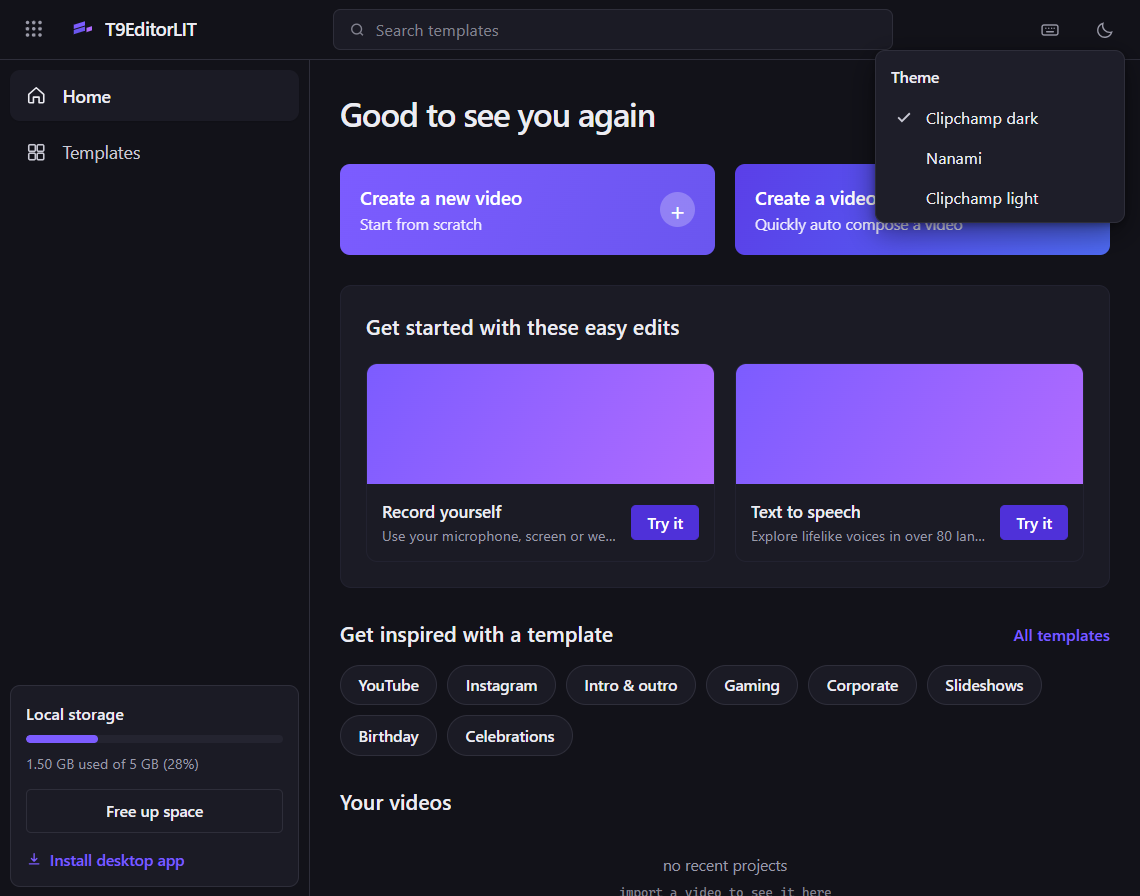

**data-theme="clipchamp" — default, Clipchamp dark**

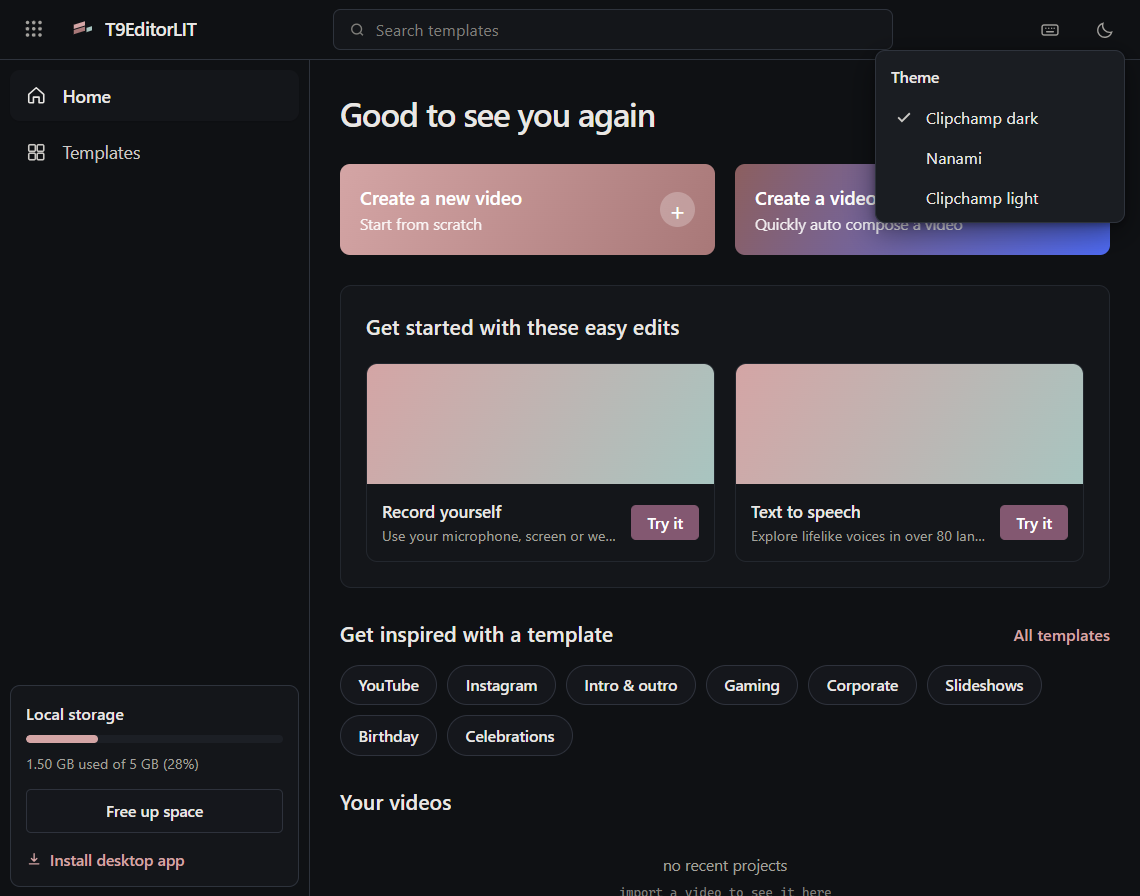

**data-theme="nanami" — charcoal + rose/gold**

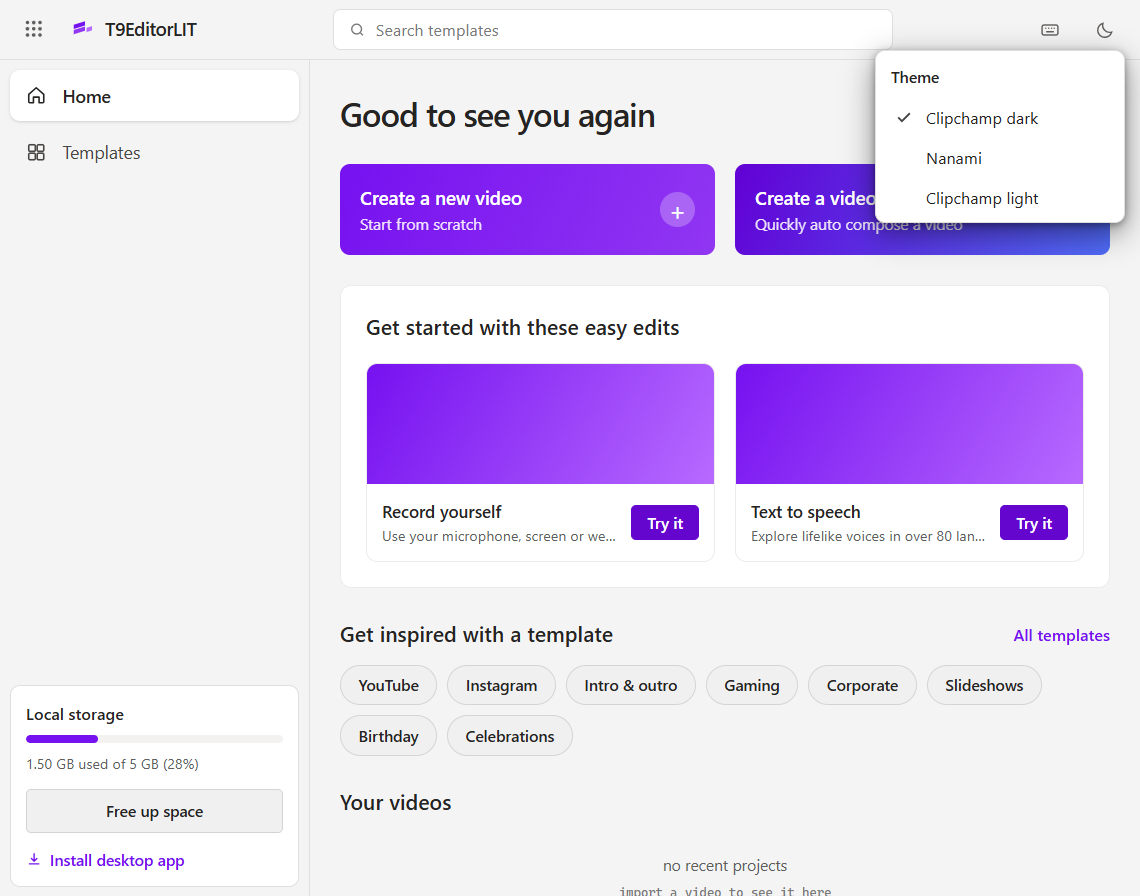

**data-theme="clipchamp-light" — shipped Fluent light tokens**

Same DOM, same component tree, same classes — the only difference between the three images is the value of one attribute on `<html>`.

## Token roles

| Token | Role | Light-theme note |
| --- | --- | --- |
| `--color-cc-bg` | App chrome background | `#121219` dark → `#f4f4f4` light |
| `--color-cc-sunken` | Recessed areas (timeline bed, rail) | one step darker than `bg` |
| `--color-cc-surface` | Panels and cards | dark `#1b1b25`, light `#ffffff` |
| `--color-cc-tint` | Hover / selected rows | sits between surface and menu |
| `--color-cc-menu` | Floating layers (menus, popovers) | one step *above* the panel |
| `--color-cc-line` / `-soft` | Hairlines, 1px borders | theme-matched greys |
| `--color-cc-text` … `-4` | Four text emphasis steps | all ≥ 4.5:1 on their own surface |
| `--color-cc-purple` | Accent: focus, indicator, border | never text |
| `--color-cc-btn` / `-hover` | Filled primary button | AA with white text |
| `--color-cc-link` | Accent text on a panel | bright end of the ramp |
| `--color-cc-lilac` / `-blush` | Decorative fills only | — |
| `--color-cc-keep` / `-cut` / `-review` | Transcript decisions | each checked against its `-dim` |

## Code 1 of 5 — `src/app.css`: the tokens and the three palettes

In [ ]:
/* ══════════════════════════════════════════════════════════════════
   Clipchamp port — DARK by default.

   ONE token namespace (`--color-cc-*`), THREE themes. Components are
   written once against the names; only the values swap:

     data-theme="clipchamp"        Clipchamp dark  (default)
     data-theme="nanami"           charcoal + rose/gold — T9's own look
     data-theme="clipchamp-light"  the shipped app's real light tokens

   Dark values are the ones the user settled on in
   resource_Clipchamp/clipchamp_test.html (his own working prototype, so
   they are chosen, not eyeballed by us). Light values were extracted from
   the shipped app with REA — see docs/CLIPCHAMP_REA_REFERENCE.md.

   `@theme static` forces Tailwind to emit every token even when the only
   reference is a `var(--color-cc-…)` inside a component's SVG attribute;
   without it a token can silently resolve to nothing and the fill vanishes.
   ══════════════════════════════════════════════════════════════════ */

@theme static {
  /* Surfaces, top to bottom: chrome → stage → panel → hover. */
  --color-cc-bg: #121219;
  --color-cc-sunken: #0c0c11;
  --color-cc-surface: #1b1b25;
  --color-cc-tint: #242430;
  /* Floating layers (menus, popovers) sit one step above the panel so a
     menu opened over the sidebar still reads as lifted. */
  --color-cc-menu: #1e1e29;

  /* Hairlines. */
  --color-cc-line: #2e2e3a;
  --color-cc-line-soft: #222230;

  /* Text. Every step below clears 4.5:1 on --color-cc-surface. */
  --color-cc-text: #ececf2;
  --color-cc-text-2: #c9c9d4;
  --color-cc-text-3: #9a9aa8;
  --color-cc-text-4: #82828f;

  /* The purple ramp. Roles, not a light→dark gradient, because dark UIs
     need the *opposite* ordering from light ones for the same jobs:

       purple     brand accent — focus rings, the rail indicator, borders.
                  Never carries text on a panel; see link for that.
       purple-2   gradient stop that carries WHITE text (CTA cards).
       purple-3   second gradient stop, same constraint.
       btn        filled primary button background — AA with white.
       btn-hover  its hover state.
       link       accent TEXT on a panel — the bright end, so 13px links
                  on --color-cc-surface still clear 4.5:1.
       lilac      decorative fills only (empty-state art, thumbnails).
       blush      decorative fills only. */
  --color-cc-purple: #7c5cff;
  --color-cc-purple-2: #5b3fe8;
  --color-cc-purple-3: #6a56ef;
  --color-cc-btn: #4f31d9;
  --color-cc-btn-hover: #6a48e6;
  --color-cc-link: #9d84ff;
  --color-cc-lilac: #b06bff;
  --color-cc-blush: #d0b4ff;

  /* Decision ramp: the three states a transcript line can be worked on.
     Green = keep, red = cut, amber = "the AI flagged this but you kept it,
     look again". Amber sits deliberately between the other two so the eye
     reads it as undecided rather than as a third decision.

     `-dim` is the chip background the matching text sits on; each pair is
     contrast-checked as a pair, which is why the dims are near-black
     rather than pastel here — pastel dims are a light-theme device. */
  --color-cc-keep: #3ddc84;
  --color-cc-keep-dim: #16261c;
  --color-cc-cut: #ff5a5a;
  --color-cc-cut-dim: #2a1418;
  --color-cc-review: #ffce4d;
  --color-cc-review-dim: #3a3016;
}

/* ── Nanami: charcoal + rose/gold. ─────────────────────────────────────────
   Same jobs, T9's palette. Kept unlayered on purpose — Tailwind emits
   `@theme` into `@layer theme`, and unlayered rules outrank any layer, so
   this beats the block above on the same element regardless of order. */
[data-theme="nanami"] {
  --color-cc-bg: #0f1114;
  --color-cc-sunken: #0b0d10;
  --color-cc-surface: #14161a;
  --color-cc-tint: #1c1f25;
  --color-cc-menu: #1a1d22;

  --color-cc-line: #2e333c;
  --color-cc-line-soft: #23272e;

  --color-cc-text: #e9e7e4;
  --color-cc-text-2: #cbc9c5;
  --color-cc-text-3: #a3a19d;
  --color-cc-text-4: #7f7e7a;

  --color-cc-purple: #d4a5a5;
  --color-cc-purple-2: #8c5f5f;
  --color-cc-purple-3: #a87878;
  --color-cc-btn: #8c5f5f;
  --color-cc-btn-hover: #a87878;
  --color-cc-link: #e0b8b8;
  --color-cc-lilac: #a8c5c0;
  --color-cc-blush: #f0dcd8;

  --color-cc-keep: #e0b64c;
  --color-cc-keep-dim: #3a3018;
  --color-cc-cut: #e0645f;
  --color-cc-cut-dim: #3d1c1a;
  --color-cc-review: #a8c5c0;
  --color-cc-review-dim: #1f2e2c;
}

/* ── Clipchamp light: the shipped app's real Fluent tokens. ─────────────── */
[data-theme="clipchamp-light"] {
  --color-cc-bg: #f4f4f4;
  --color-cc-surface: #ffffff;
  --color-cc-sunken: #faf9f8;
  --color-cc-tint: #f3f2f1;
  --color-cc-menu: #ffffff;

  --color-cc-line: #e1dfdd;
  --color-cc-line-soft: #edebe9;

  --color-cc-text: #252423;
  --color-cc-text-2: #484644;
  --color-cc-text-3: #605e5c;
  --color-cc-text-4: #797979;

  --color-cc-purple: #7611f0;
  --color-cc-purple-2: #6200d5;
  --color-cc-purple-3: #9136f2;
  --color-cc-btn: #6200d5;
  --color-cc-btn-hover: #5600b8;
  --color-cc-link: #6200d5;
  --color-cc-lilac: #b76aff;
  --color-cc-blush: #ecb4ff;

  --color-cc-keep: #1f9d55;
  --color-cc-keep-dim: #d9f0e3;
  --color-cc-cut: #d93a30;
  --color-cc-cut-dim: #fadfdd;
  --color-cc-review: #c98500;
  --color-cc-review-dim: #fdeecb;
}

/* Native widget painting follows the active theme: form controls,
   selection and the scrollbars Chrome draws itself. */
html {
  color-scheme: dark;
}
html[data-theme="clipchamp-light"] {
  color-scheme: light;
}

@layer components {
  /* Everything below lives inside .cc-shell, so the Nanami dark chrome
     (top bar, mode panels) keeps its own untouched palette. */
  .cc-shell {
    background-color: var(--color-cc-bg);
    color: var(--color-cc-text);
    font-family: "Segoe UI", "Inter", system-ui, sans-serif;
    /* Inherited from <html>: dark for clipchamp/nanami, light only when
       data-theme="clipchamp-light". Re-declaring it as `light` here is what
       made the old dark build paint light scrollbars + form controls. */
    color-scheme: inherit;
  }

  .cc-shell ::-webkit-scrollbar {
    background-color: transparent;
  }
  .cc-shell ::-webkit-scrollbar-thumb {
    background-color: var(--color-cc-line);
    border-radius: 4px;
  }
  .cc-shell ::-webkit-scrollbar-thumb:hover {
    background-color: var(--color-cc-text-4);
  }

## Code 2 of 5 — `src/app.html`: the shell

Note the `<html data-theme="clipchamp">` default. See the pitfalls section at the bottom for a very real bug this file once caused.

In [ ]:
<!doctype html>
<html lang="en" class="dark" data-theme="clipchamp">
  <head>
    <meta charset="utf-8" />
    <link rel="icon" href="%sveltekit.assets%/favicon.png" />
    <meta name="viewport" content="width=device-width, initial-scale=1" />
    <meta name="color-scheme" content="dark" />
    <title>T9EditorLIT</title>
    <!--
      Restore the saved theme before the first paint.

      This has to be a separate file rather than an inline <script>:
      tauri.conf.json ships `script-src 'self'`, which blocks inline
      execution. Running before the page body means the <html>
      background already matches the chosen theme when the WebView
      paints, so switching from a light theme never flashes dark.
    -->
    <script src="%sveltekit.assets%/theme-init.js"></script>
    %sveltekit.head%
  </head>
  <body data-sveltekit-preload-data="hover">
    <div style="display: contents">%sveltekit.body%</div>
  </body>
</html>

## Code 3 of 5 — `static/theme-init.js`: restore before first paint

In [ ]:
/*
 * Pre-hydration theme restore.
 *
 * Loaded by src/app.html as a plain (non-module) script so it runs before
 * the first paint. tauri.conf.json sets `script-src 'self'`, which forbids
 * an inline script, hence the separate file.
 *
 * Must stay in sync with the THEMES list in src/lib/stores/theme.svelte.ts:
 * an unknown or absent value falls back to "clipchamp", the same default
 * the <html> tag carries, so a first-run user sees no change at all.
 */
(function () {
  var THEMES = ["clipchamp", "nanami", "clipchamp-light"];
  var stored = null;
  try {
    stored = localStorage.getItem("t9-theme");
  } catch (err) {
    stored = null; // private mode / storage disabled — keep the default
  }
  var theme = THEMES.indexOf(stored) >= 0 ? stored : "clipchamp";
  document.documentElement.setAttribute("data-theme", theme);
  // Keep the UA's own widget painting (form controls, scrollbars) in step;
  // CSS sets `color-scheme` too, but this one applies before CSS loads.
  var meta = document.querySelector('meta[name="color-scheme"]');
  if (meta) meta.setAttribute("content", theme === "clipchamp-light" ? "light" : "dark");
})();

## Code 4 of 5 — `src/lib/stores/theme.svelte.ts`: the runtime switch

In [ ]:
/**
 * Theme switch for the Clipchamp shell.
 *
 * Three palettes share ONE token namespace (`--color-cc-*`, see app.css);
 * switching only rewrites `<html data-theme>`, so no component knows which
 * theme is up and nothing needs to re-render — the cascade does the work.
 *
 *   clipchamp       Clipchamp dark        (default)
 *   nanami          charcoal + rose/gold  (T9's own look)
 *   clipchamp-light the shipped app's real light tokens
 *
 * `t9-theme` is read before first paint by static/theme-init.js; this store
 * is the writer, and it applies the attribute immediately on construction
 * so a theme set mid-session takes effect without waiting for an effect.
 */

export type ThemeId = "clipchamp" | "nanami" | "clipchamp-light";

/** Cycles in this order when the toggle button is pressed. */
const ORDER: readonly ThemeId[] = ["clipchamp", "nanami", "clipchamp-light"];

const STORAGE_KEY = "t9-theme";

export const THEME_LABEL: Record<ThemeId, string> = {
  clipchamp: "Clipchamp dark",
  nanami: "Nanami",
  "clipchamp-light": "Clipchamp light",
};

function isTheme(value: string | null): value is ThemeId {
  return value !== null && (ORDER as readonly string[]).includes(value);
}

function readStored(): ThemeId {
  try {
    const stored = localStorage.getItem(STORAGE_KEY);
    if (isTheme(stored)) return stored;
  } catch {
    // Storage unavailable (private mode) — fall through to the default.
  }
  return "clipchamp";
}

class ThemeStore {
  current = $state<ThemeId>("clipchamp");

  constructor() {
    this.apply(readStored());
  }

  private apply(id: ThemeId): void {
    this.current = id;
    document.documentElement.setAttribute("data-theme", id);
    const meta = document.querySelector('meta[name="color-scheme"]');
    if (meta) meta.setAttribute("content", id === "clipchamp-light" ? "light" : "dark");
    try {
      localStorage.setItem(STORAGE_KEY, id);
    } catch {
      // Persisting is best-effort; the in-session switch still works.
    }
  }

  set(id: ThemeId): void {
    if (id === this.current) return;
    this.apply(id);
  }

  /** Next palette in the cycle — also what the toggle button's tooltip shows. */
  toggle(): void {
    const index = ORDER.indexOf(this.current);
    this.apply(ORDER[(index + 1) % ORDER.length]);
  }

  get next(): ThemeId {
    const index = ORDER.indexOf(this.current);
    return ORDER[(index + 1) % ORDER.length];
  }
}

export const theme = new ThemeStore();

## Code 5 of 5 — wiring a toggle into a component

Moon/Sun button + radio menu, from `CcTopBar.svelte`. Store access is just an import; there is no context provider and no dispatch.

In [ ]:
    {#if open === "theme"}
      <CcMenu align="end" label="Theme" onclose={() => (open = null)}>
        <div class="px-2 py-1.5">
          <span class="text-[12.5px] font-semibold text-cc-text">Theme</span>
        </div>
        {#each THEMES as id (id)}
          <button
            type="button"
            class="cc-menu-item"
            role="menuitemradio"
            aria-checked={theme.current === id}
            onclick={() => {
              theme.set(id);
              open = null;
            }}
          >
            <span class="cc-menu-icon">
              {#if theme.current === id}
                <svg
                  width="16"
                  height="16"
                  viewBox="0 0 24 24"
                  fill="none"
                  stroke="currentColor"
                  stroke-width="2.2"
                  aria-hidden="true"
                >
                  <path d="m5 12.5 4.5 4.5L19 7.5" />
                </svg>
              {/if}
            </span>
            <span class="cc-menu-text">{THEME_LABEL[id]}</span>
          </button>
        {/each}
      </CcMenu>

Using the tokens in markup — this is the whole component-facing API:

```svelte
<div class="bg-cc-surface text-cc-text border-cc-line border">
  <a class="text-cc-link">Open</a>
  <button class="cc-btn-primary bg-cc-btn text-white">Export</button>
  <span class="bg-cc-keep-dim text-cc-keep">keep</span>
</div>
```

No component ever mentions a theme id. That is the point.

## Dropping this into another project

1. Copy the `@theme static` block and the two `[data-theme=…]` overrides into your CSS entry point (Tailwind v4 required).
2. Put `<html class="dark" data-theme="clipchamp">` and `<meta name="color-scheme" content="dark">` in your HTML shell.
3. Drop `theme-init.js` into `static/` and load it from `<head>` — **not** deferred, not a module; it must beat the first paint.
4. Copy `theme.svelte.ts` and export `theme` + `THEME_LABEL`.
5. Add a toggle button that calls `theme.toggle()` or `theme.set(id)`.
6. Rewrite your components to use `cc-*` tokens only. Delete every raw hex you find — a raw hex is a theme that will not switch.
7. Verify (see below).

## Pitfalls — bugs we actually hit, so you don't have to

- **Never write `%sveltekit.body%` (or any `%sveltekit.*%`) inside `src/app.html`, even in a comment.** The dev transform replaces the *first* occurrence in the file. Ours was inside an HTML comment describing this very theme script, so the client boot script got injected into the comment, the real body placeholder never rendered, and the app came up as a black screen with **zero console errors**. Symptom to remember: `document.body.innerText` is empty and the only DOM is a literal `%sveltekit.body%`.
- **Inline `<script>` is blocked in the Tauri shell** (`script-src 'self'`). Any pre-hydration logic has to be a separate file in `static/`.
- **`getCurrentWebview()` throws outside Tauri.** Running `vite dev` in a plain browser means `"__TAURI_INTERNALS__" in window` is false — guard it, or one uncaught `TypeError` takes down the whole `$effect` that registered your drop listener.
- **Keep the theme code out of `{#key}` blocks.** Mode isolation destroys and rebuilds that subtree; a store defined inside it would be recreated (and re-read `localStorage`) on every switch.
- **`.ipynb` breaks `prettier --check .`** with `No parser could be inferred`. `*.ipynb` is listed in `.prettierignore` for that reason — keep it there or CI goes red on a documentation file.

## Verification (CI/CD)

```powershell
npm run verify:fast   # prettier + svelte-check + node --test + cargo check
```

Last run: **exit 0** — prettier clean, svelte-check 0 errors / 0 warnings, 14/14 node tests, `cargo check` clean (4 pre-existing dead-code warnings only).

Python is banned repo-wide (AGENTS.md §2), which is also why this notebook is built by PowerShell rather than by a `nbformat` script.